# Online Shoppers: EDA

COGS 118D final project, Option 1. Data: UCI Online Shoppers Purchasing Intention (id 468), https://archive.ics.uci.edu/dataset/468

One row = one browsing session on one online store. Outcome = `Revenue` (did the session end in a purchase).

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

## Load

In [2]:
df = pd.read_csv("data/online_shoppers_intention.csv")
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.dtypes.to_frame('dtype').T

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,object,int64,int64,int64,int64,object,bool,bool


## Cleaning checks

In [4]:
print("missing values:", int(df.isna().sum().sum()))
print("exact duplicate rows:", int(df.duplicated().sum()))
print("negative durations:", int((df.filter(like="Duration") < 0).sum().sum()))
df["VisitorType"].value_counts()

missing values: 0
exact duplicate rows: 125
negative durations: 0


VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

In [5]:
# Recode for modeling: 0/1 outcome, short visitor label. "Other" (85 rows) is dropped later, if at all.
df["bought"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
df["visitor"] = df["VisitorType"].map({"Returning_Visitor": "Returning", "New_Visitor": "New", "Other": "Other"})
df["any_pagevalue"] = (df["PageValues"] > 0).astype(int)
print("purchase rate:", round(df["bought"].mean(), 3))

purchase rate: 0.155


## Numeric summary

Everything is right-skewed: medians sit far below means, and `PageValues` is 0 for most sessions.

In [6]:
num = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
       "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
df[num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


In [7]:
print("share of sessions with PageValues == 0:", round((df["PageValues"] == 0).mean(), 3))
df.groupby("bought")[num].median().round(3)

share of sessions with PageValues == 0: 0.779


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
bought,,,,,,,,,,
0,0.0,0.000,0.0,0.0,16.0,510.190,0.004,0.029,0.000,0.0
1,2.0,52.367,0.0,0.0,29.0,1109.906,0.000,0.016,16.758,0.0


## Purchase rate by visitor type

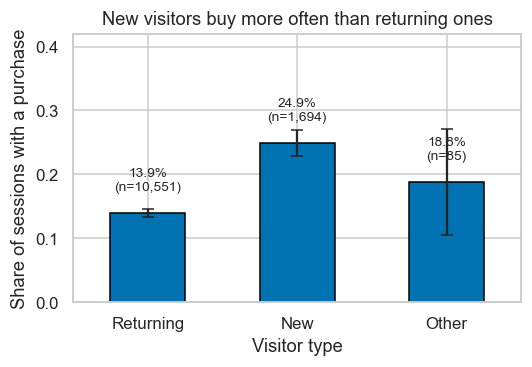

,n,rate,se
visitor,,,
Returning,10551,0.139,0.003
New,1694,0.249,0.011
Other,85,0.188,0.042


In [8]:
def rate_table(col):
    t = df.groupby(col, observed=True)["bought"].agg(n="size", rate="mean")
    t["se"] = np.sqrt(t["rate"] * (1 - t["rate"]) / t["n"])
    return t

vt = rate_table("visitor").loc[["Returning", "New", "Other"]]
ax = vt["rate"].plot.bar(yerr=1.96 * vt["se"], capsize=4, rot=0, figsize=(5, 3.5), edgecolor="black")
for i, (r, n) in enumerate(zip(vt["rate"], vt["n"])):
    ax.text(i, r + 0.035, f"{r:.1%}\n(n={n:,})", ha="center", fontsize=9)
ax.set(xlabel="Visitor type", ylabel="Share of sessions with a purchase", ylim=(0, 0.42),
       title="New visitors buy more often than returning ones")
plt.tight_layout(); plt.savefig("figures/rate_by_visitor.png", dpi=200); plt.show()
vt.round(3)

## PageValues (main predictor)

`PageValues` = Google Analytics average value of the pages viewed in the session. It is 0 unless the session touched a page that tends to lead to a purchase.

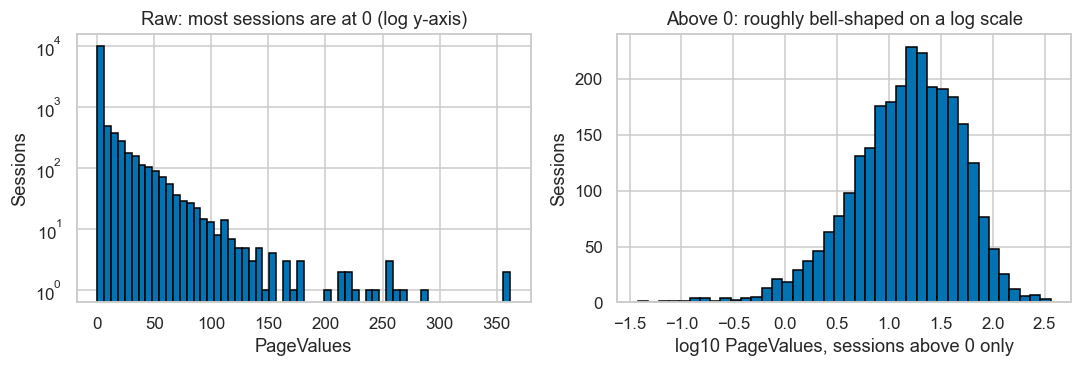

,n,rate,se
any_pagevalue,,,
0,9600,0.039,0.002
1,2730,0.563,0.009


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["PageValues"], bins=60, edgecolor="black")
axes[0].set(xlabel="PageValues", ylabel="Sessions", yscale="log", title="Raw: most sessions are at 0 (log y-axis)")
pos = df[df["PageValues"] > 0]
axes[1].hist(np.log10(pos["PageValues"]), bins=40, edgecolor="black")
axes[1].set(xlabel="log10 PageValues, sessions above 0 only", ylabel="Sessions", title="Above 0: roughly bell-shaped on a log scale")
plt.tight_layout(); plt.show()
rate_table("any_pagevalue").round(3)

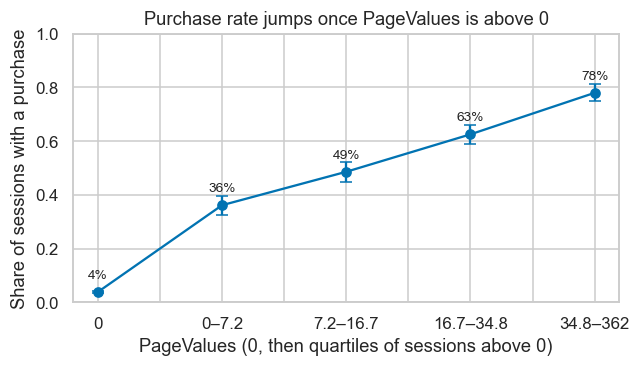

,n,rate,se
pv_bin,,,
0,9600,0.039,0.002
0–7.2,680,0.362,0.018
7.2–16.7,687,0.486,0.019
16.7–34.8,681,0.626,0.019
34.8–362,682,0.780,0.016


In [10]:
# Purchase rate across PageValues bins: 0, then quartiles of the positive values
edges = [-0.001, 0] + list(pos["PageValues"].quantile([.25, .5, .75]).round(1)) + [df["PageValues"].max()]
labels = ["0"] + [f"{a:.3g}–{b:.3g}" for a, b in zip(edges[1:-1], edges[2:])]
df["pv_bin"] = pd.cut(df["PageValues"], bins=edges, labels=labels)
pv = rate_table("pv_bin")
ax = pv["rate"].plot(marker="o", yerr=1.96 * pv["se"], capsize=4, figsize=(6, 3.5))
for i, r in enumerate(pv["rate"]):
    ax.text(i, r + 0.05, f"{r:.0%}", ha="center", fontsize=9)
ax.set(xlabel="PageValues (0, then quartiles of sessions above 0)", ylabel="Share of sessions with a purchase",
       ylim=(0, 1), title="Purchase rate jumps once PageValues is above 0")
plt.tight_layout(); plt.savefig("figures/rate_by_pagevalues.png", dpi=200); plt.show()
pv.round(3)

## PageValues × visitor type (moderation preview)

Does the PageValues effect differ for new vs. returning visitors? Lines that are not parallel hint at an interaction.

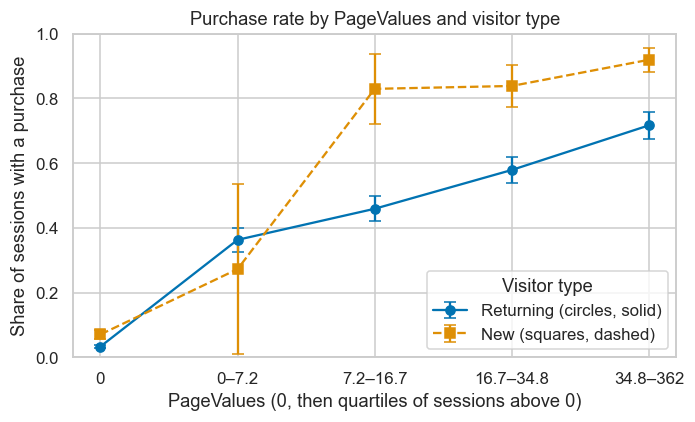

n             rate          
visitor       New Returning    New Returning
pv_bin                                      
0          1313.0    8218.0  0.071     0.033
0–7.2        11.0     669.0  0.273     0.363
7.2–16.7     47.0     638.0  0.830     0.459
16.7–34.8   124.0     556.0  0.839     0.579
34.8–362    199.0     470.0  0.920     0.717

In [11]:
two = df[df["visitor"].isin(["Returning", "New"])]
g = two.groupby(["pv_bin", "visitor"], observed=True)["bought"].agg(n="size", rate="mean").reset_index()
g["se"] = np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, mk, ls in [("Returning", "o", "-"), ("New", "s", "--")]:
    s = g[g["visitor"] == name]
    ax.errorbar(range(len(s)), s["rate"], yerr=1.96 * s["se"], marker=mk, linestyle=ls, capsize=4, label=f"{name} ({'circles, solid' if mk == 'o' else 'squares, dashed'})")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set(xlabel="PageValues (0, then quartiles of sessions above 0)", ylabel="Share of sessions with a purchase", ylim=(0, 1),
       title="Purchase rate by PageValues and visitor type")
ax.legend(title="Visitor type")
plt.tight_layout(); plt.savefig("figures/rate_by_pagevalues_visitor.png", dpi=200); plt.show()
g.pivot(index="pv_bin", columns="visitor", values=["n", "rate"]).round(3)

## Other predictors

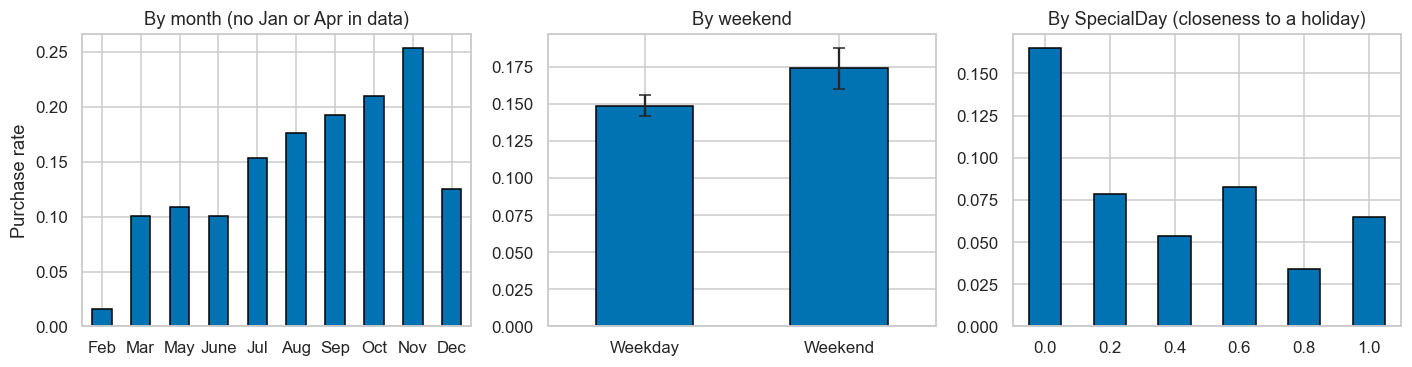

n   rate     se
Month      Feb        184  0.016  0.009
           Mar       1907  0.101  0.007
           May       3364  0.109  0.005
           June       288  0.101  0.018
           Jul        432  0.153  0.017
           Aug        433  0.176  0.018
           Sep        448  0.192  0.019
           Oct        549  0.209  0.017
           Nov       2998  0.254  0.008
           Dec       1727  0.125  0.008
Weekend    Weekday   9462  0.149  0.004
           Weekend   2868  0.174  0.007
SpecialDay 0.0      11079  0.165  0.004
           0.2        178  0.079  0.020
           0.4        243  0.053  0.014
           0.6        351  0.083  0.015
           0.8        325  0.034  0.010
           1.0        154  0.065  0.020

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
m = rate_table("Month").loc[order]
m["rate"].plot.bar(ax=axes[0], rot=0, edgecolor="black"); axes[0].set(title="By month (no Jan or Apr in data)", ylabel="Purchase rate", xlabel="")
w = rate_table("Weekend"); w.index = ["Weekday", "Weekend"]
w["rate"].plot.bar(ax=axes[1], rot=0, yerr=1.96 * w["se"], capsize=4, edgecolor="black"); axes[1].set(title="By weekend", xlabel="")
sd = rate_table("SpecialDay")
sd["rate"].plot.bar(ax=axes[2], rot=0, edgecolor="black"); axes[2].set(title="By SpecialDay (closeness to a holiday)", xlabel="")
plt.tight_layout(); plt.show()
pd.concat({"Month": m, "Weekend": w, "SpecialDay": sd}).round(3)

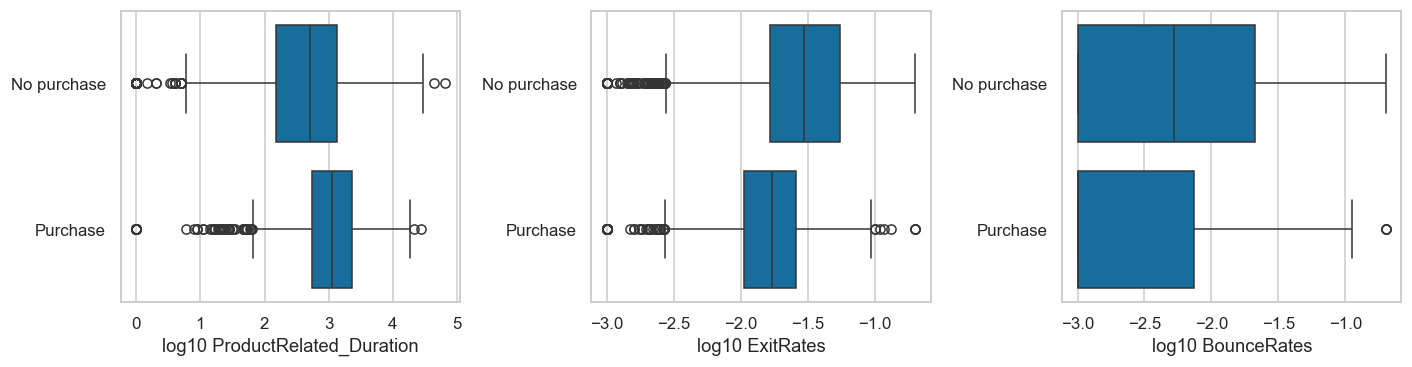

In [13]:
# Bounce / exit rates and time on product pages, split by outcome (log x because of the skew)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["ProductRelated_Duration", "ExitRates", "BounceRates"]):
    sns.boxplot(data=df, y=df["bought"].map({0: "No purchase", 1: "Purchase"}), x=np.log10(df[col] + (1 if "Duration" in col else 0.001)), ax=ax)
    ax.set(xlabel=f"log10 {col}", ylabel="")
plt.tight_layout(); plt.show()

## Correlations between predictors

Spearman, because of the skew. Pairs near ±1 should not both go in one model.

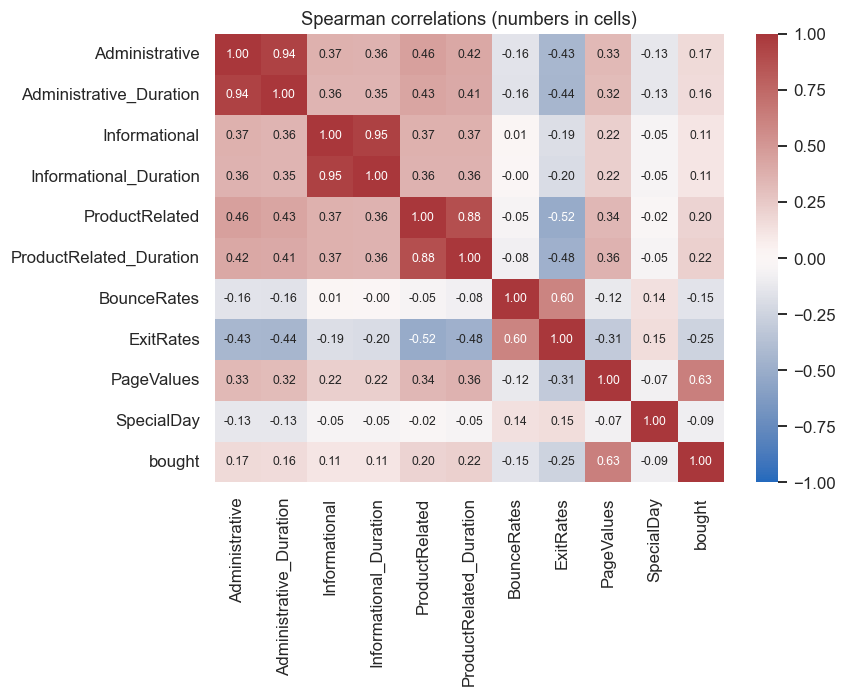

PageValues                 0.626
ExitRates                 -0.254
ProductRelated_Duration    0.217
ProductRelated             0.199
Administrative             0.168
Administrative_Duration    0.164
BounceRates               -0.149
Informational              0.114
Informational_Duration     0.112
SpecialDay                -0.087
Name: bought, dtype: float64

In [14]:
corr = df[num + ["bought"]].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Spearman correlations (numbers in cells)"); plt.tight_layout(); plt.show()
corr["bought"].drop("bought").sort_values(key=abs, ascending=False).round(3)